## EDA Analysis
- Goal - we are doing the EDA for the creating the predective model for the smartphone.

In [134]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [135]:
plt.style.available

['Solarize_Light2',
 '_classic_test_patch',
 '_mpl-gallery',
 '_mpl-gallery-nogrid',
 'bmh',
 'classic',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot',
 'grayscale',
 'petroff10',
 'seaborn-v0_8',
 'seaborn-v0_8-bright',
 'seaborn-v0_8-colorblind',
 'seaborn-v0_8-dark',
 'seaborn-v0_8-dark-palette',
 'seaborn-v0_8-darkgrid',
 'seaborn-v0_8-deep',
 'seaborn-v0_8-muted',
 'seaborn-v0_8-notebook',
 'seaborn-v0_8-paper',
 'seaborn-v0_8-pastel',
 'seaborn-v0_8-poster',
 'seaborn-v0_8-talk',
 'seaborn-v0_8-ticks',
 'seaborn-v0_8-white',
 'seaborn-v0_8-whitegrid',
 'tableau-colorblind10']

In [136]:
plt.style.use('bmh')

In [137]:
df=pd.read_csv(r'/content/cleaned_smartphone_data.csv')

In [138]:
pd.set_option('display.max_column',None)

In [139]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 879 entries, 0 to 878
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   name                       879 non-null    object 
 1   brand_name                 879 non-null    object 
 2   price                      879 non-null    float64
 3   specs                      879 non-null    float64
 4   has_4g                     879 non-null    bool   
 5   has_5g                     879 non-null    bool   
 6   has_ir_blaster             879 non-null    bool   
 7   has_nfc                    879 non-null    bool   
 8   num_cores                  879 non-null    int64  
 9   processor_speed            801 non-null    float64
 10  ram_capacity               879 non-null    int64  
 11  internal_memory            879 non-null    object 
 12  processor_brand            879 non-null    object 
 13  fast_cahrging_available    879 non-null    int64  

In [140]:
df['specs']=df.specs.apply(lambda x:np.nan if x == 63 else x)

In [141]:
df.rename(columns={'specs':'rating'},inplace=True)

1.brand_name

In [142]:
df.brand_name.value_counts()

,count
brand_name,
samsung,143
realme,123
oppo,98
vivo,73
xiaomi,69
poco,59
motorola,58
oneplus,38
apple,35


<Axes: xlabel='brand_name'>

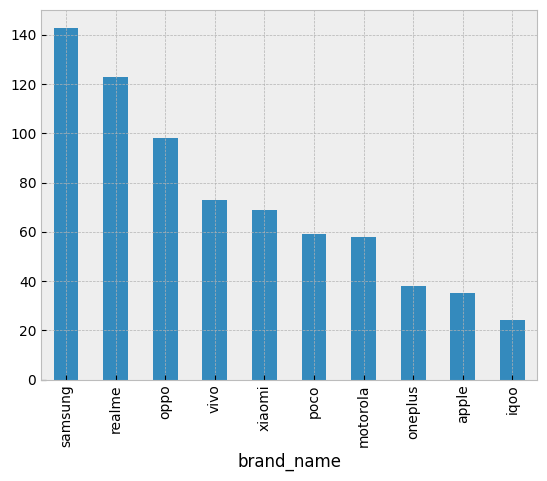

In [143]:
# Univariate Analysis
df.brand_name.value_counts().head(10).plot(kind='bar')

<Axes: ylabel='count'>

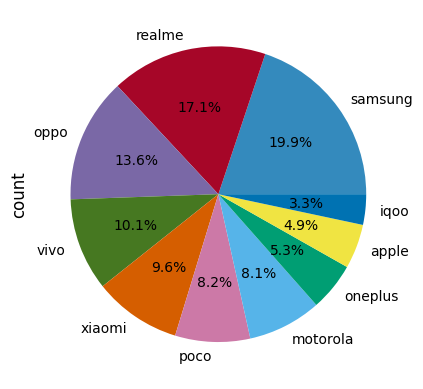

In [144]:
df.brand_name.value_counts().head(10).plot(kind='pie',autopct='%2.1f%%')

In [145]:
df.brand_name.isnull().sum()

np.int64(0)

## conclusion
-> As you can see in the bar plot the smasung have the mosst phones in the market 19.9% phones are from samsun in the top 10. then realme and then oppo and then vivo and then xiaome.


### name
We cannot do like on this because it have all unique values


In [146]:
df.name.nunique()

859

## price

In [147]:
df.price.describe()

,price
count,879.000000
mean,41368.245734
std,43665.484000
min,6499.000000
25%,17999.000000
50%,28990.000000
75%,44999.000000
max,449900.000000


 As in this you can see the data is righ skewed price max is very high so we have to cross check it again.

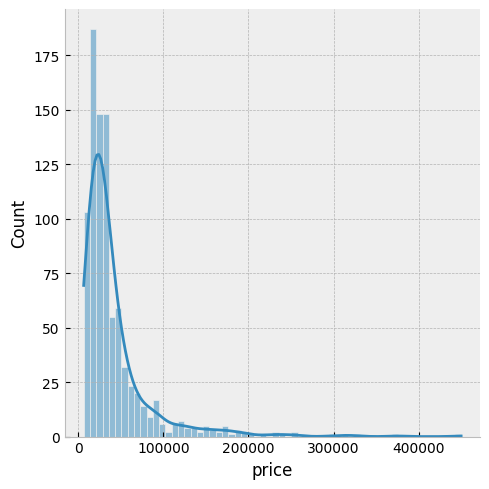

In [148]:
sns.displot(kind='hist',data=df,x='price',kde=True)

As you can see in the plot the data is right skewed as the highest more mobiles are in the range 0 to 1 lakh and less mobiles in the 3lakh to 4lakh.

<Axes: ylabel='price'>

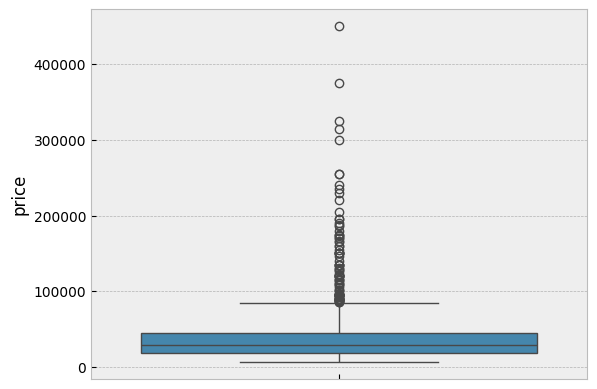

In [149]:
sns.boxplot(df.price)

As you can see in the plot the because of that the real rnage are dosent shown properly so we have to check the outliers in the df.

In [150]:
df[df.price>200000]

,name,brand_name,price,rating,has_4g,has_5g,has_ir_blaster,has_nfc,num_cores,processor_speed,ram_capacity,internal_memory,processor_brand,fast_cahrging_available,battery_capacity,fast_charging,refresh_rate,extended_memory_available,extended_upto,screen_size,resolution,os,num_rear_cameras,num_front_cameras,primary_camera_rear,primary_camera_front,intrnal_memory
156,Apple iPhone Duo (2TB),apple,449900.0,NaN,False,True,False,True,6,NaN,12,2TB,bionic,1,5800.0,NaN,120.0,0,NaN,7.60,1878 x 2670,ios 27,3,1,48.0,NaN,12.0
245,Apple iPhone Duo,apple,299900.0,NaN,False,True,False,True,6,NaN,12,256.0,bionic,1,5800.0,NaN,120.0,0,NaN,7.60,1878 x 2670,ios 27,3,1,48.0,NaN,12.0
310,Vivo X Fold 6,vivo,219999.0,NaN,False,True,True,True,8,4.21,12,512.0,dimensity,1,6900.0,80.0,120.0,0,NaN,8.02,2312 x 2504,android v17,3,1,200.0,20.0,12.0
383,Apple iPhone 18 Pro Max (1TB),apple,254900.0,NaN,False,True,False,True,6,4.93,12,1TB,bionic,1,5391.0,NaN,120.0,0,NaN,6.90,1320 x 2868,ios v27,3,1,48.0,18.0,12.0
394,Apple iPhone Duo (1TB),apple,374900.0,NaN,False,True,False,True,6,NaN,12,1TB,bionic,1,5800.0,NaN,120.0,0,NaN,7.60,1878 x 2670,ios 27,3,1,48.0,NaN,12.0
395,Apple iPhone 18 Pro Max (512GB),apple,204900.0,NaN,False,True,False,True,6,4.93,12,512.0,bionic,1,5391.0,NaN,120.0,0,NaN,6.90,1320 x 2868,ios v27,3,1,48.0,18.0,12.0
469,Samsung Galaxy Z Fold 8 Ultra (16GB RAM + 1TB),samsung,254999.0,NaN,False,True,False,True,8,4.74,16,1TB,snapdragon,1,5000.0,45.0,120.0,0,NaN,8.00,2256 x 2504,android v17,3,1,200.0,10.0,16.0
530,Apple iPhone Duo (512GB),apple,324900.0,NaN,False,True,False,True,6,NaN,12,512.0,bionic,1,5800.0,NaN,120.0,0,NaN,7.60,1878 x 2670,ios 27,3,1,48.0,NaN,12.0
710,Apple iPhone 18 Pro (2TB),apple,314900.0,NaN,False,True,False,True,6,4.93,12,2TB,bionic,1,4056.0,NaN,120.0,0,NaN,6.30,1206 x 2622,ios v27,3,1,48.0,18.0,12.0
716,Samsung Galaxy Z Fold 8 (16GB RAM + 1TB),samsung,234999.0,NaN,False,True,False,True,8,4.74,16,1TB,snapdragon,1,4800.0,45.0,120.0,0,NaN,7.60,1828 x 2448,android v17,3,1,50.0,10.0,16.0


In [151]:
has_foldable=df.name.apply(lambda n:True if ('Fold' in n or 'Duo' in n)  else False)

In [152]:
df.insert(8,'has_foldable',has_foldable)

## I done this column becuase of the some phones have the dual display or foldable display have the higher prices.

In [153]:
df.price.isnull().sum()

np.int64(0)

## Rating

In [154]:
df.rating.describe()

,rating
count,574.000000
mean,63.564460
std,8.176405
min,50.000000
25%,57.000000
50%,64.000000
75%,70.000000
max,80.000000


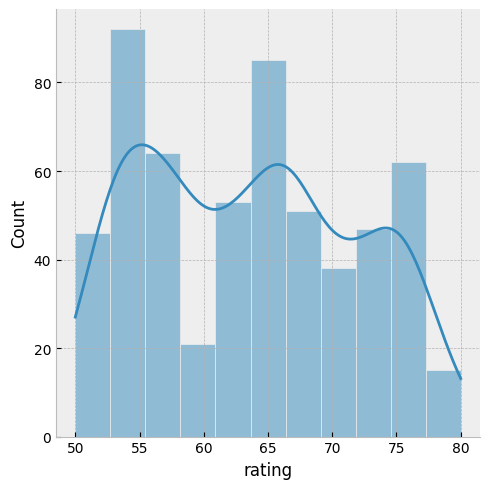

In [155]:
sns.displot(kind='hist',data=df,x='rating',kde=True)

In plot looks like its closer to normal_distribution.

In [156]:
df.rating.skew()

np.float64(0.14996732243043415)

<Axes: ylabel='rating'>

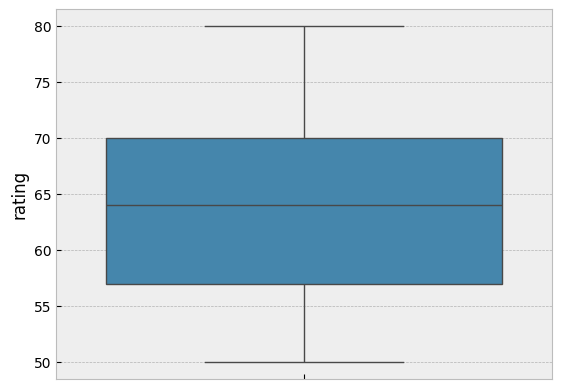

In [157]:
sns.boxplot(df.rating)

As the data is nearly normal distributed so the it dont have the outliers.

In [158]:
df.rating.isnull().sum()/897

np.float64(0.34002229654403565)

As you can see the main problem in the rating ferature is the null values

In this arounbd 34% values are null

 so we have to fill that we have the three ways

1.simple way is that it was filled with the mean

2.In this we fill the particular brand with their mean rating apple rating mean samsung rating mean like That.

3.ML models in sklearn.

In [159]:
df.drop(columns='has_4g',inplace=True)

## has_5g

<Axes: ylabel='count'>

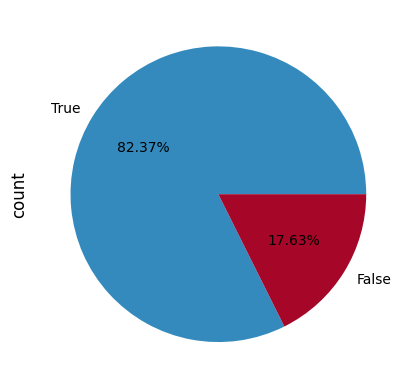

In [160]:
df.has_5g.value_counts().plot(kind='pie',autopct='%1.2f%%')

As seeingthis pie chart we know that the market of the 4g phones are reducing by 2022 so we not gona see the 4g or loer network phones than this 🛜.

# has_ir_blaster

<Axes: ylabel='count'>

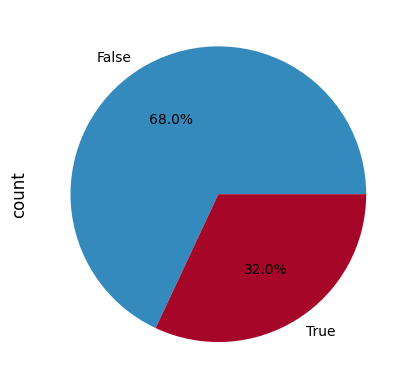

In [161]:
df.has_ir_blaster.value_counts().plot(kind='pie',autopct='%2.1f%%')

In [162]:
df[df.has_ir_blaster==True]['brand_name'].value_counts()

,count
brand_name,
xiaomi,52
oppo,51
vivo,45
poco,44
realme,27
oneplus,17
tecno,15
iqoo,15
infinix,11


In [163]:
df.has_ir_blaster.isnull().sum()

np.int64(0)

Ir blaster is mostly in the chinese phones so it is the technology using that we can control the tv and other things that is mostly given by the chienese phones.

<Axes: ylabel='count'>

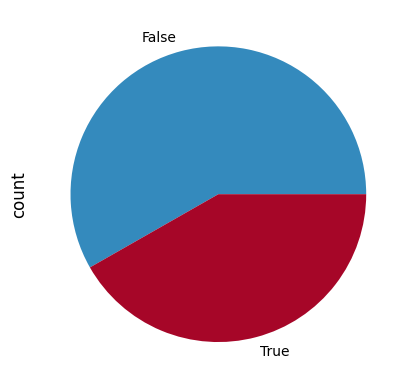

In [164]:
df.has_nfc.value_counts().plot(kind='pie')

In [165]:
(df.has_nfc.sum()/df.index.max())*100

np.float64(41.7995444191344)

This is the categorical column that shows the is a short-range wireless technology that lets electronic devices talk to each other when they touch or come within a few centimeters (typically 4 cm or less).

In Todays market the **41%** mobiles have this technology

## has_foldable

<Axes: xlabel='has_foldable', ylabel='count'>

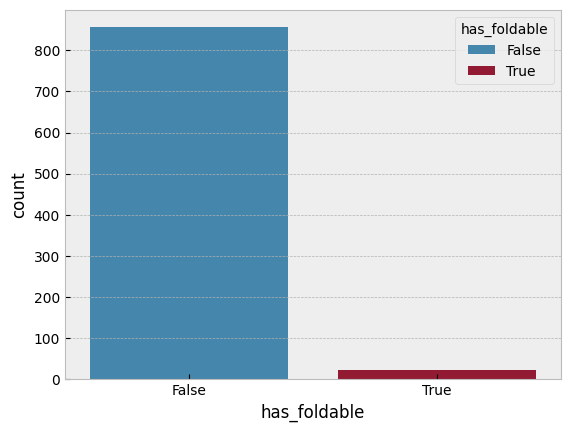

In [166]:
sns.countplot(data=df,x='has_foldable',hue='has_foldable')

In [167]:
df[df.has_foldable==True][['price','name']]

,price,name
156,449900.0,Apple iPhone Duo (2TB)
245,299900.0,Apple iPhone Duo
301,134999.0,Samsung Galaxy Z Fold 7
310,219999.0,Vivo X Fold 6
321,194999.0,Samsung Galaxy Z Fold 8 Ultra
374,174999.0,Samsung Galaxy Z Fold 8 5G
394,374900.0,Apple iPhone Duo (1TB)
469,254999.0,Samsung Galaxy Z Fold 8 Ultra (16GB RAM + 1TB)
530,324900.0,Apple iPhone Duo (512GB)
580,186999.0,Google Pixel 11 Pro Fold


In [168]:
df.has_foldable.isnull().sum()

np.int64(0)

As you can see in the above data frame and plot the foldable count is so less but we cannot ignore it why?

-> because the we are going to devlope the model some user can ask that model about the fold phones so i have to devlope that column so ml model can easily understand it as that mobile price so much higher so its have unique display or something so model can tell the close price of that smartphone as in that column the higest price of mobile is the Apple duo somewhere about 4.5Lakh so it become the outlier but its useful in that data does it is foldable then model can give accurate value it does not **"hallucinate"**.

But if have the phones that have something another thing like it have the **gold or diamond plated** phones or **parthnership phones with big brands**(like Lamborghini,porsche) with high prices ill drop that rows because we are devloping model that get the specifications in the input from the user not the mobile has gold plated or something else.

## num_cores

<Axes: ylabel='count'>

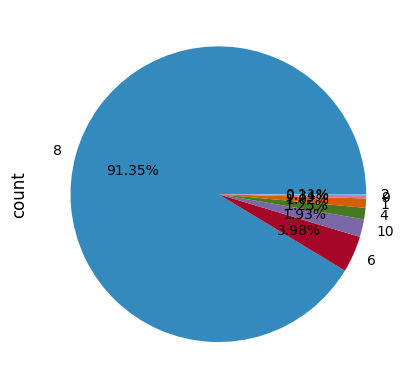

In [169]:
df.num_cores.value_counts().plot(kind='pie',autopct='%2.2f%%')

In [170]:
df.num_cores.isnull().sum()

np.int64(0)

In the num_cores column we have the 91% market is filled with the 8 cores(octa cores).

In [171]:
df.processor_speed.describe()

,processor_speed
count,801.000000
mean,2.659625
std,0.630634
min,1.300000
25%,2.400000
50%,2.400000
75%,2.840000
max,4.930000


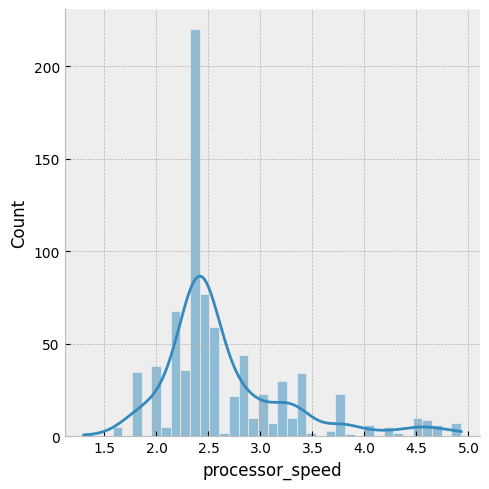

In [172]:
sns.displot(kind='hist',data=df,x='processor_speed',kde=True)

In [173]:
df.processor_speed.skew()

np.float64(1.534704452656395)

<Axes: ylabel='processor_speed'>

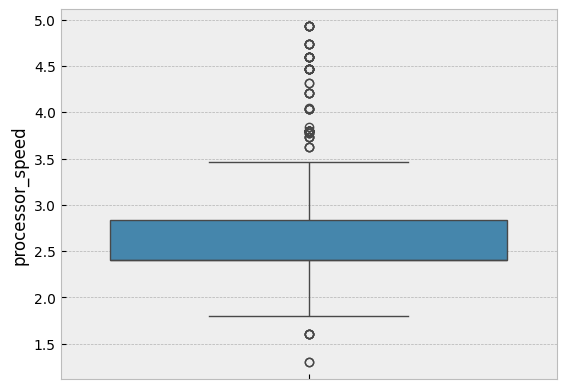

In [174]:
sns.boxplot(df.processor_speed)

In [175]:
df.processor_speed.isnull().sum()

np.int64(78)

- Processor speed is in the GHz the most phones have the 2.5 some good and  ultra premium flagship  phones 📱 have the 5.0 GHz speed.

- One problem is  column contain 78 null values

- we do not remove the outliers because that arte actual phones that havce this much processor speed.

## ram_capacity

In [176]:
df.ram_capacity.value_counts()

,count
ram_capacity,
8,324
4,178
6,165
12,161
16,28
3,18
2,4
10,1


In [177]:
df.ram_capacity.describe()

,ram_capacity
count,879.000000
mean,7.674630
std,3.089578
min,2.000000
25%,6.000000
50%,8.000000
75%,8.000000
max,16.000000


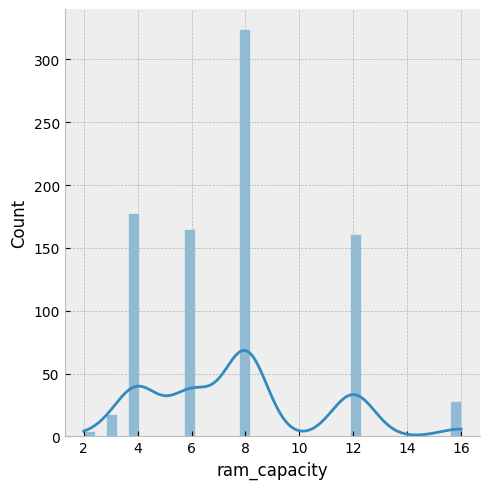

In [178]:
sns.displot(kind='hist',data=df,x='ram_capacity',kde=True)


<Axes: ylabel='ram_capacity'>

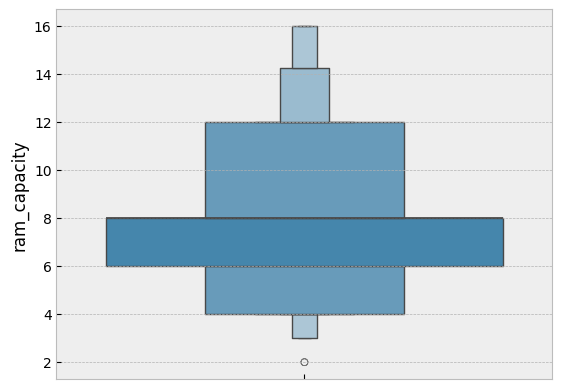

In [179]:
sns.boxenplot(df.ram_capacity)

In [180]:
df.ram_capacity.isnull().sum()

np.int64(0)

- Most mobile have the 8 GB ram some smartphones have the less than 4 gb that is rare although and some flagship have the 16 gb that also normal.

- Here is every thing is weel and fine as all is correct the outliers is only 1 but its the genuine value that does not affect the model.

- It does not have the null values.

## Internal_Memory

In [181]:
df['internal_memory']=df.internal_memory.str.replace('GB','').str.replace('TB','')

In [182]:
df['internal_memory']=df.internal_memory.apply(lambda tb:1024*tb if (tb == 1.0 or tb == 2.0) else tb ).astype(float)


In [183]:
df.internal_memory.value_counts()

,count
internal_memory,
128.0,395
256.0,278
64.0,122
512.0,61
32.0,11
1.0,8
2.0,3
16.0,1


In [184]:
df.internal_memory.describe()

,internal_memory
count,879.000000
mean,183.333333
std,115.183113
min,1.000000
25%,128.000000
50%,128.000000
75%,256.000000
max,512.000000


In [185]:
df.drop(columns='intrnal_memory',inplace=True)

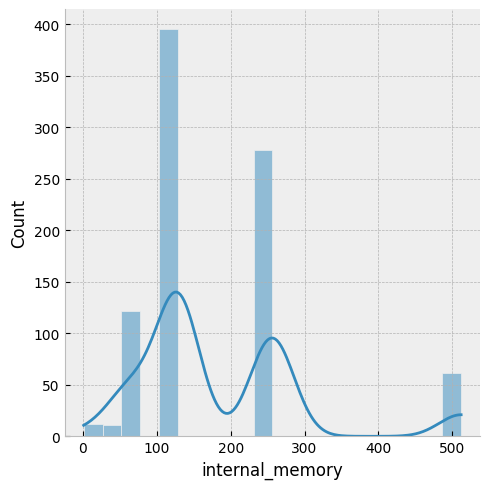

In [186]:
sns.displot(kind='hist',data=df,x='internal_memory',kde=True)

<Axes: ylabel='internal_memory'>

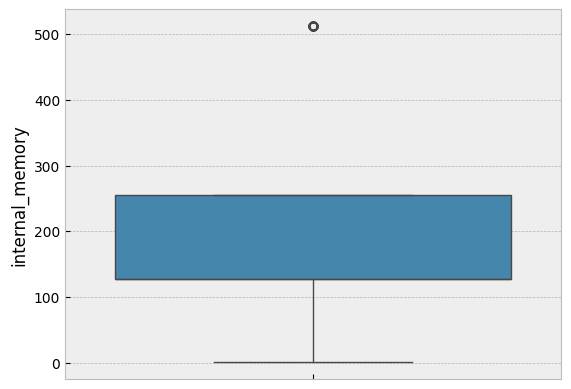

In [187]:
sns.boxplot(df.internal_memory)

In [188]:
df.internal_memory.isnull().sum()

np.int64(0)

- This feature is complitely ok so it shows that most smartphones have the 128 to 250 GB internal_memory but some high end phones have the 1024 and 2048 gb ram.


## processor_brand

In [189]:
def brand_extractor(brand):

  if brand == 'dimensity':
    return 'dimensity'

  elif brand == 'snapdragon':
    return 'snapdragon'

  elif brand == 'unisoc':
    return 'unisoc'

  elif brand == 'exynos':
    return 'exynos'

  elif brand == 'helio':
    return 'helio'

  elif brand == 'bionic':
    return 'bionic'

  elif brand == 'tensor':
    return 'tensor'

  else:
    return 'other'

In [190]:
df['processor_brand']=df.processor_brand.str.replace('tiger','unisoc').str.replace('spreadtrum','unisoc').apply(brand_extractor)

<Axes: ylabel='count'>

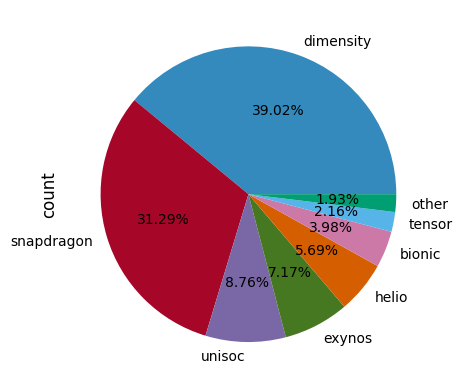

In [191]:
df.processor_brand.value_counts().plot(kind='pie',autopct='%2.2f%%')

In [192]:
df.processor_brand.isnull().sum()

np.int64(0)

- This column look completly ok now the most market is filkled with the dimensity brand as its the medium range and as  apple is expensive that is only 3.98% only.

## fast_charging_available


In [193]:
df.fast_cahrging_available.value_counts()

,count
fast_cahrging_available,
1,855
0,24


<Axes: ylabel='count'>

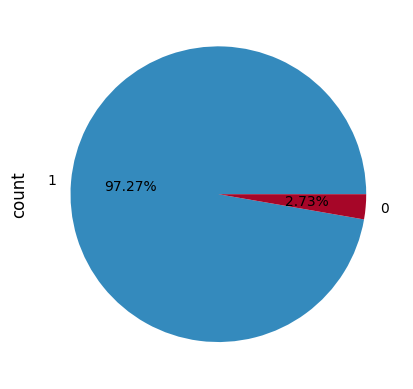

In [194]:
df.fast_cahrging_available.value_counts().plot(kind='pie',autopct='%1.2f%%')

In [195]:
df.fast_cahrging_available.isnull().sum()

np.int64(0)

- In this feature the in the market almost all phones have the fast chargig thats mean in future there is strong chance that all phones have the fast charging.

## battery_capacity

In [196]:
df.battery_capacity.describe()

,battery_capacity
count,879.000000
mean,5808.080774
std,1267.349474
min,1821.000000
25%,5000.000000
50%,5600.000000
75%,6950.000000
max,10001.000000


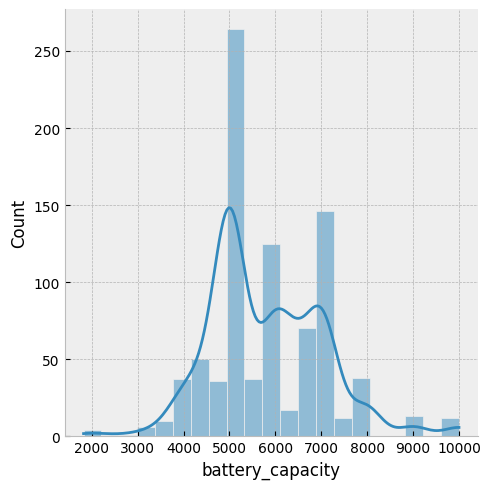

In [197]:
sns.displot(kind='hist',data=df,x='battery_capacity',kde=True)

<Axes: ylabel='battery_capacity'>

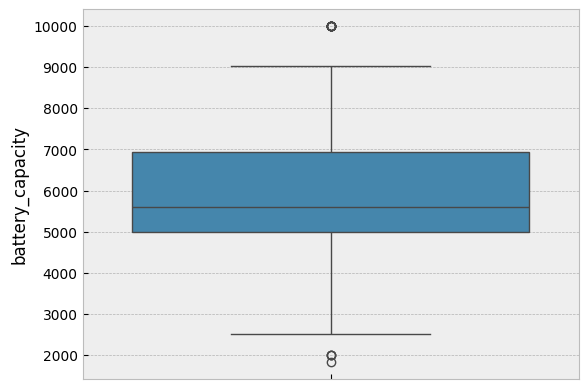

In [198]:
sns.boxplot(df.battery_capacity)

In [199]:
df.battery_capacity.skew()

np.float64(0.5724094343196359)

In [200]:
df.battery_capacity.isna().sum()

np.int64(0)

- This feature is the neary normal distribution as most phones are comes with the 5000 mah battery and the less phones comes with the large battery. As increasing the battery increase the size of the smartphone.

## fast_charging

In [201]:
df.fast_charging.describe()

,fast_charging
count,794.000000
mean,47.338791
std,28.004140
min,10.000000
25%,25.000000
50%,45.000000
75%,68.000000
max,150.000000


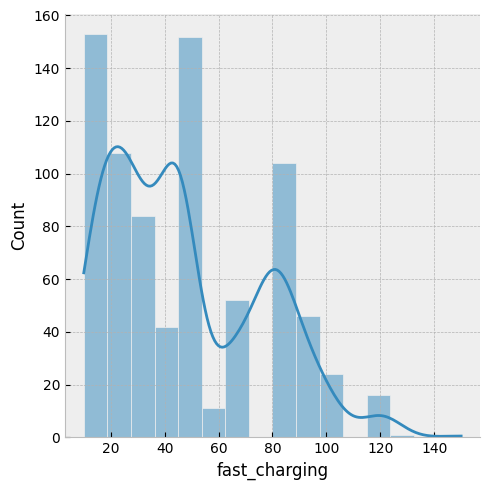

In [202]:
sns.displot(kind='hist',data=df,x='fast_charging',kde=True)

<Axes: ylabel='fast_charging'>

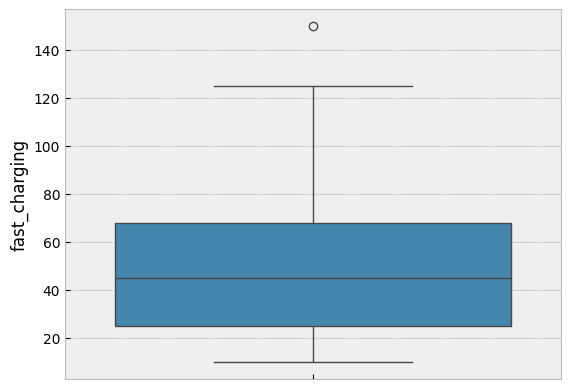

In [203]:
sns.boxplot(df.fast_charging)

In [204]:
df.fast_charging.skew()

np.float64(0.6863317809243644)

In [205]:
df.fast_charging.isnull().sum()

np.int64(85)

- In the market there is normally the charger given the around 45 to 65 watt mostly.

- This column is for if fast charging avaolable then how much it is.

- The null values are nothing but that are not disclosed by the companies so later we fill with diffrent techniques.

## refresh_rate

In [206]:
df['refresh_rate']=df.refresh_rate.astype('category')

<Axes: ylabel='count'>

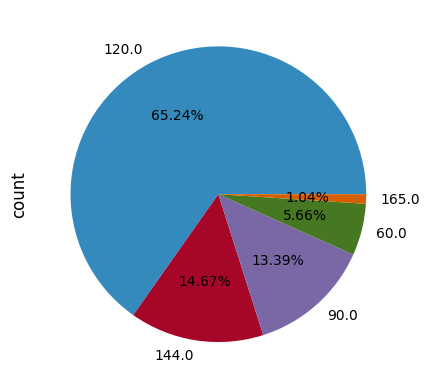

In [207]:
df.refresh_rate.value_counts().plot(kind='pie',autopct='%1.2f%%')

In [208]:
df.refresh_rate.isnull().sum()

np.int64(13)

- In this feature/column As per the market the 65% phones comes with the 120 refresh_rate and some gaming phones have the 165 rate 60is seen less as todays games and customers have more smoother exxperience.

## extended_memory_available

In [209]:
df.extended_memory_available.value_counts()

,count
extended_memory_available,
1,521
0,358


<Axes: xlabel='extended_memory_available'>

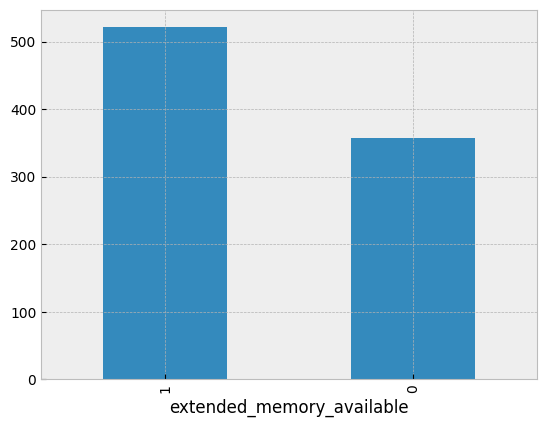

In [210]:
df.extended_memory_available.value_counts().plot(kind='bar')

In [211]:
(df.extended_memory_available.sum()/df.index.max()).item()*100

59.33940774487472

In [212]:
df.extended_memory_available.isnull().sum()

np.int64(0)

- In this feature have the does this smartphone have the extended memory slot if yes -> 1 No -> 0.

- And as you can see in the plot there is 59% smartphones have the card slots.

## extended_upto

In [213]:
df.extended_upto.describe()

,extended_upto
count,450.000000
mean,1079.313333
std,680.713930
min,1.000000
25%,1024.000000
50%,1024.000000
75%,2048.000000
max,2048.000000


In [214]:
df.extended_upto.value_counts()

,count
extended_upto,
1024.0,221
2048.0,114
1.0,59
256.0,18
512.0,17
128.0,14
1536.0,7


<Axes: ylabel='count'>

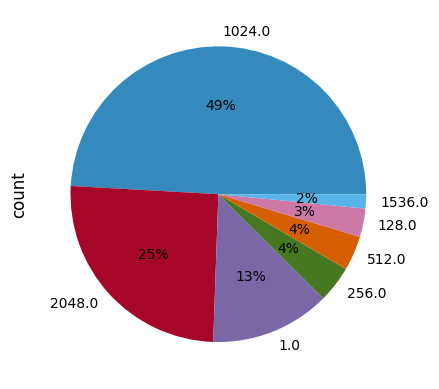

In [215]:
df.extended_upto.value_counts().plot(kind='pie',autopct='%1.0f%%')

In [216]:
df.extended_upto.isna().sum()

np.int64(429)

- In this column have the values that extended_memory_available is 1 then its have the values in that 1 tb is nostly available in the market 49% smartphone have the 1tb card.

- 1 is **supports micro SD slot**

## screen_size

In [217]:
df.screen_size.describe()

,screen_size
count,879.000000
mean,6.666678
std,0.492342
min,1.770000
25%,6.600000
50%,6.700000
75%,6.780000
max,8.300000


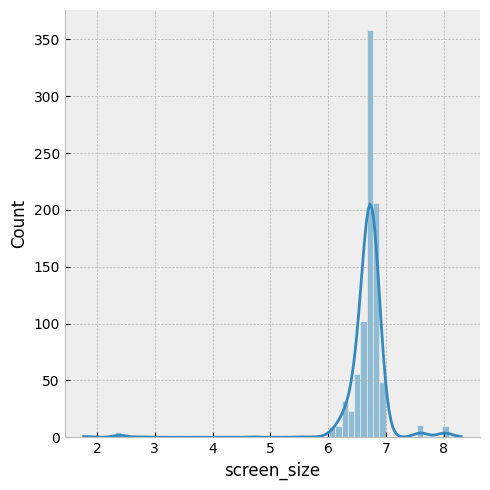

In [218]:
sns.displot(kind='hist',data=df,x='screen_size',kde=True)

In [219]:
df.screen_size.skew()

np.float64(-6.2323482721071635)

<Axes: ylabel='screen_size'>

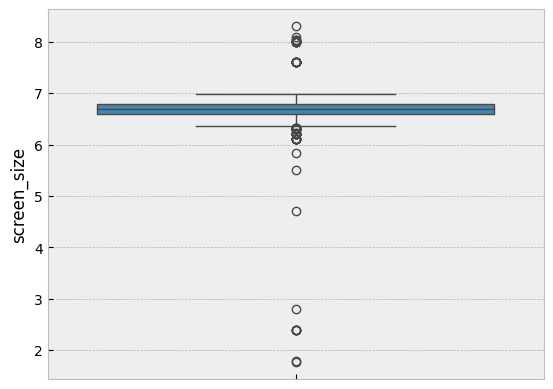

In [220]:
sns.boxplot(df.screen_size)

In [221]:
df.screen_size.isnull().sum()

np.int64(0)

- In this column the display size is present the normal range of the smartphone displays are between 6 to 7 and some less phones have the 8 inch display.

- As the 6 to 7 is most phones have the displays so data is left skewed.

- And there are outliers but that are normal.

## resolution

In [222]:
df['resplution']=df.resolution.str.strip()

In [223]:
df.loc[595,'resolution']='720 × 1570'

In [224]:
dims=df.resolution.str.strip().str.extract(r'(\d+)\s*[xX×]\s*(\d+)').astype(int)

In [225]:
res_width=dims.min(axis=1)

In [226]:
res_height=dims.max(axis=1)

In [227]:
df.insert(20,'res_width',res_width)

In [228]:
df.insert(21,'res_height',res_height)

In [229]:
temp_df=df[df.res_width <= 500]

In [230]:
width = [np.nan, 412, 320, np.nan, np.nan, np.nan, 320, 720]
height = [np.nan, 920, 480, np.nan, np.nan, np.nan, 480, 1640]

In [231]:
df.loc[temp_df.index,'res_width']=width

/tmp/ipykernel_606/425411112.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[nan, 412, 320, nan, nan, nan, 320, 720]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[temp_df.index,'res_width']=width


In [232]:
df.loc[temp_df.index,'res_height']=height

/tmp/ipykernel_606/488307874.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[nan, 920, 480, nan, nan, nan, 480, 1640]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[temp_df.index,'res_height']=height


In [233]:
df.drop(columns='resolution',inplace=True)

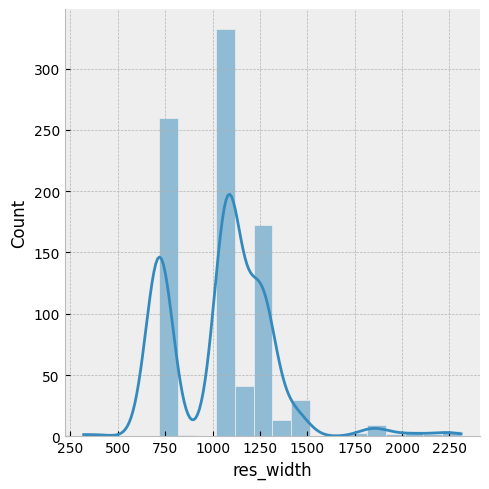

In [234]:
sns.displot(kind='hist',data=df,x='res_width',kde=True)

<Axes: ylabel='res_width'>

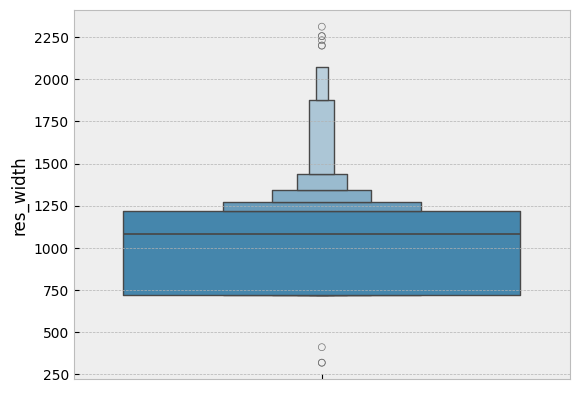

In [235]:
sns.boxenplot(df.res_width)

In [236]:
df.res_width.isnull().sum()

np.int64(4)

In [237]:
df.res_height.describe()

,res_height
count,875.000000
mean,2265.760000
std,492.338419
min,480.000000
25%,1604.000000
50%,2400.000000
75%,2670.000000
max,3216.000000


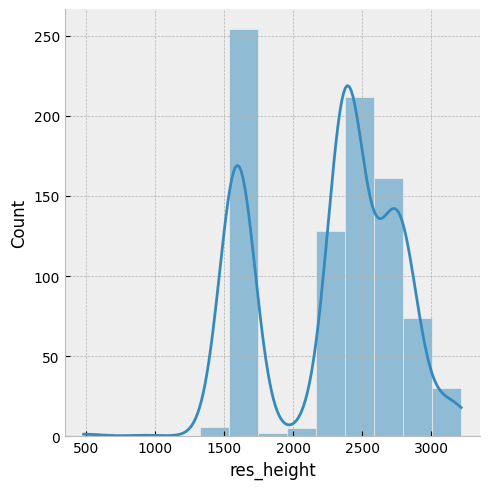

In [238]:
sns.displot(kind='hist',data=df,x='res_height',kde=True)

<Axes: ylabel='res_height'>

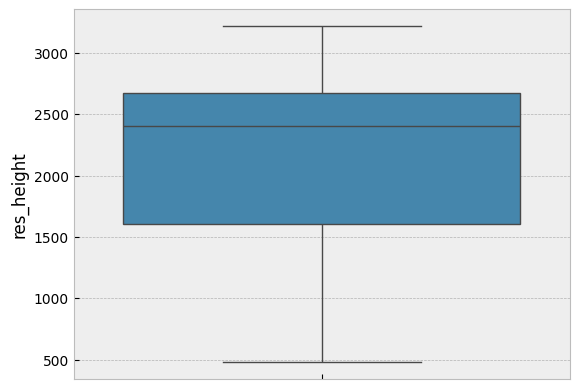

In [239]:
sns.boxplot(df.res_height)

In [240]:
df.res_height.isnull().sum()

np.int64(4)

- Both columns are having the 4 missing value we have to fill it.

- The normal range of the resolution is the 1000 x 1700 or 2500.


## os

In [241]:
def os_cleaner(os):
  if 'android' in os:
    return 'android'

  elif 'ios' in os:
    return 'ios'

  else:
    return 'other'

In [242]:
df['os']=df.os.apply(os_cleaner).astype(str)

In [243]:
df.os

,os
0,android
1,android
2,android
3,android
4,android
...,...
874,android
875,ios
876,android
877,android


<Axes: ylabel='count'>

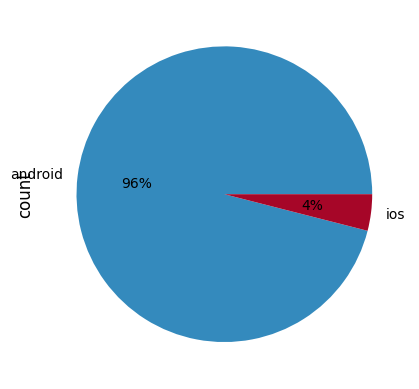

In [244]:
df.os.value_counts().plot(kind='pie',autopct='%1.0f%%')

In [245]:
df.os.isnull().sum()

np.int64(0)

- In this feature tells that the most market is having the android phones and less ios.

In [246]:
df.drop(columns='resplution',inplace=True)

## num_rear_cameras

<Axes: ylabel='count'>

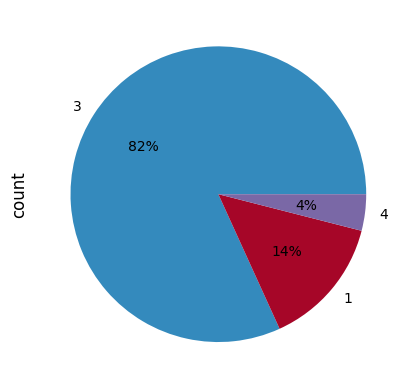

In [247]:
df.num_rear_cameras.value_counts().plot(kind='pie',autopct='%1.0f%%')

In [248]:
df.num_rear_cameras.isnull().sum()

np.int64(0)

- In this column the mostly smartphone have the 3 cameras in the rear so you can say its a sweet spot for the todays genration 📷.

## num_front_cameras

In [249]:
df.num_front_cameras.value_counts()

,count
num_front_cameras,
1,861
Missing,12
3,6


In [250]:
temp_df=df[df.num_front_cameras=='Missing']

In [251]:
df.loc[temp_df.index,'num_front_cameras']=1

In [252]:
temp_df=df[df.num_front_cameras == '3']

In [253]:
df.loc[temp_df.index,'num_front_cameras']='2'

In [254]:
df['num_front_cameras']=df.num_front_cameras.astype(str)

In [255]:
df.num_front_cameras.value_counts()

,count
num_front_cameras,
1,873
2,6


<Axes: xlabel='num_front_cameras', ylabel='count'>

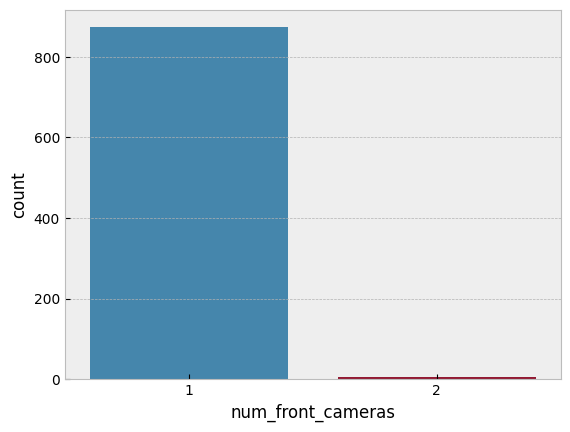

In [256]:
sns.countplot(data=df,x='num_front_cameras',hue='num_front_cameras')

<Axes: ylabel='count'>

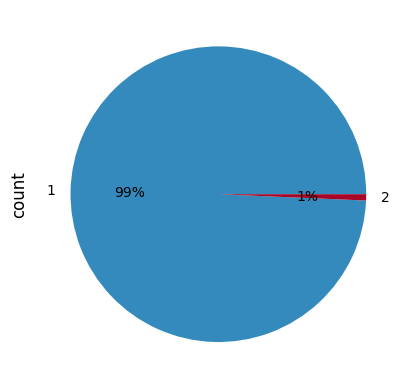

In [257]:
df.num_front_cameras.value_counts().plot(kind='pie',autopct='%1.0f%%')

-  As you can see in the plot the 1% only smartphones have the 2 cameras on the dislay.

- That means the people likes the large display rather than having the cameras on the front.

## primary_camera_rear

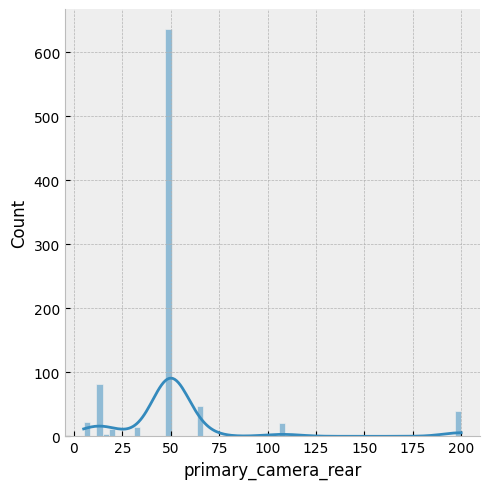

In [258]:
sns.displot(kind='hist',data=df,x='primary_camera_rear',kde=True)

<Axes: ylabel='primary_camera_rear'>

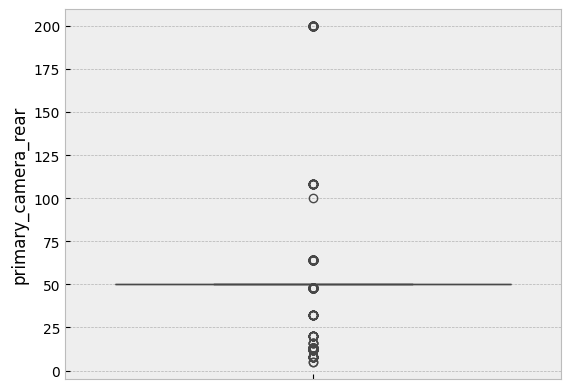

In [259]:
sns.boxplot(df.primary_camera_rear)

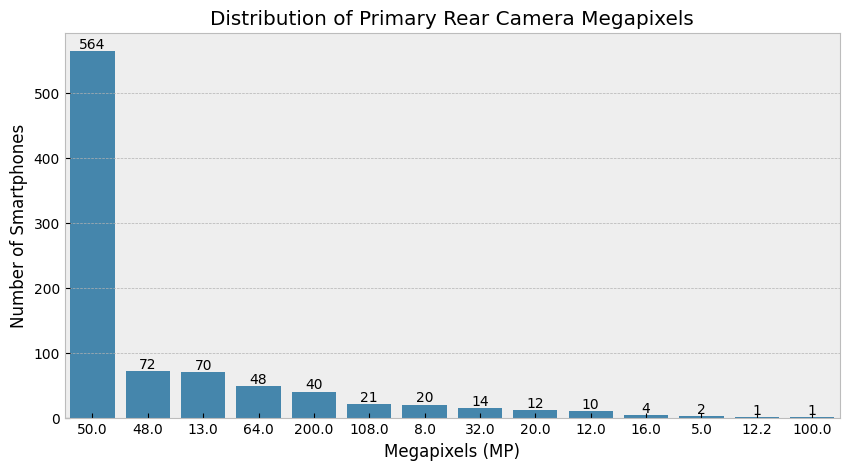

In [260]:
plt.figure(figsize=(10, 5))
order = df['primary_camera_rear'].value_counts().index
ax = sns.countplot(data=df, x='primary_camera_rear',order=order)

# Add count labels on top of each bar
ax.bar_label(ax.containers[0])
plt.title('Distribution of Primary Rear Camera Megapixels')
plt.xlabel('Megapixels (MP)')
plt.ylabel('Number of Smartphones')
plt.show()

In [261]:
df.primary_camera_rear.isnull().sum()

np.int64(0)

 As in this plot the data is distributed the 50 mb rear camera is mostly in the smartphones so its have  largest count in the data.

## primary_camera_front

In [262]:
df.primary_camera_front.value_counts()

,count
primary_camera_front,
8.0,192
32.0,143
16.0,128
5.0,90
50.0,90
13.0,64
12.0,55
20.0,36
10.0,29


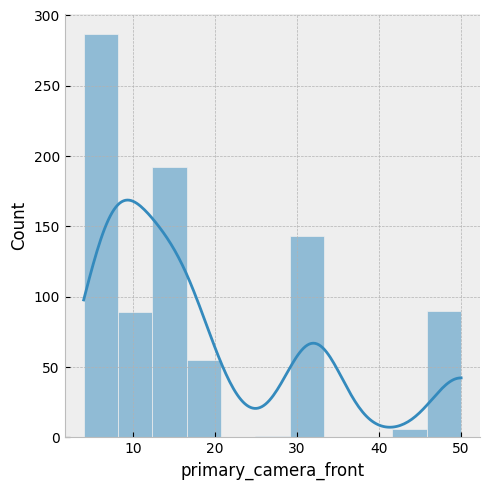

In [263]:
sns.displot(kind='hist',data=df,x='primary_camera_front',kde=True)

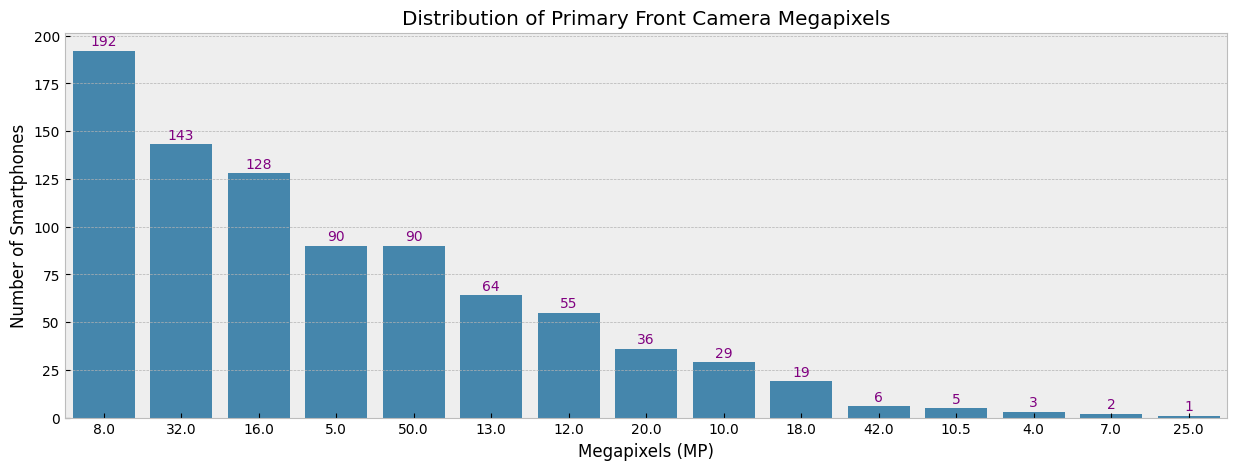

In [264]:
plt.figure(figsize=(15, 5))

order=df.primary_camera_front.value_counts().index
ax = sns.countplot(data=df,x='primary_camera_front',order=order)

ax.bar_label(ax.containers[0],padding=1.6,color='purple')
plt.title('Distribution of Primary Front Camera Megapixels')
plt.xlabel('Megapixels (MP)',fontdict={'color':'black'})
plt.ylabel('Number of Smartphones',fontdict={'color':'black'})
plt.show()

<Axes: ylabel='primary_camera_front'>

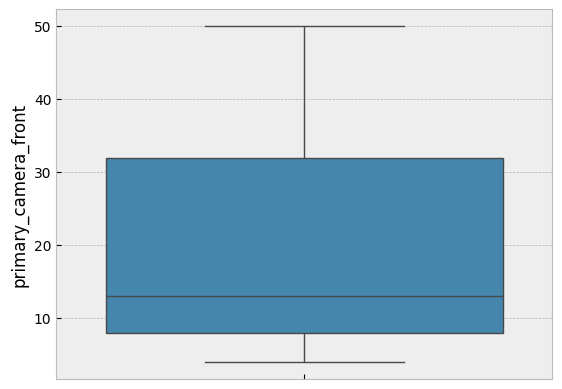

In [265]:
sns.boxplot(df.primary_camera_front)

In [266]:
df.primary_camera_front.isnull().sum()

np.int64(16)

- In this column there is 4 missing values.

- In this column the data tells us that the mejority smartphones have the 8 to 32 to 16 MP camera in the front.